# ROI-wise analysis of LeBel et al. (2023) "moth radio" fMRI data set
# sub-UTS01
## Using ROIs from Labache et al. (2019) "SENtence Supramodal Areas AtlaS" (SENSAAS) 

In [1]:
from matplotlib.pyplot import figure, cm
from IPython.display import Image
import numpy as np
import logging
from pathlib import Path
import h5py
import tables
import cortex
from cortex import mni
import nibabel as nib
from nibabel import Nifti1Image
from nilearn.image import load_img, math_img
from nilearn.maskers import NiftiMasker
np.random.seed(1234)
logging.getLogger('matplotlib.font_manager').disabled = True

fsl prefix /home/shantanu.nath/fsl/share/fsl/bin/


In [2]:
cortex.database.default_filestore

'/home/shantanu.nath/anaconda3/envs/brain_llm_3.9/share/pycortex/db'

## 1. Create set of SENSAAS ROIs in subject space
(To be run only once per subject)

### 1.1 First prepare required trasnformation matrix and reference image

In [3]:
# This transform is gonna be from one specific functional space for a subject, which is defined by the transform 'fullhead'
# subUTS01_to_mni = cortex.db.get_mnixfm('sub-UTS03', 'fullhead')

#Alternative way:
#subUTS01_to_mni = mni.compute_mni_transform(subject='sub-UTS01', xfm='fullhead')

In [5]:
# subUTS01_to_mni is a 4x4 array describing the transformation in homogeneous coords
# subUTS01_to_mni.shape

In [6]:
# Create a random dataset in subject space
# randdata = cortex.Volume.random('sub-UTS01', 'fullhead')
# randdata.shape

In [7]:
# Transform random dataset into MNI space (creates a nibabel Nifti1Image)
# mni_randdata = mni.transform_to_mni(randdata, subUTS01_to_mni)
# mni_randdata.shape

In [8]:
# Save mni_randdata for use outside python
# mni_randdata.to_filename('/dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/transforms/subUTS01_mni_randdata.nii')

### (((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((((

### 1.2 Outside python, map ROIs to Lebel et al. (2023) MNI image dimensions
(I have already done this)
#### 1.2.1 Have SENSAAS ROIs in MNI space
#### 1.2.2 In SPM25, run "moth_fMRI_by_ROI_SPM25batch_step1.2.mat" to coregister-reslice each SENSAAS ROI onto subUTS01_mni_randdata.nii (from voxsize 222 to 111)

### 1.3 Outside python, in SPM25 with CAT12.9.2577 installed, run "moth_fMRI_by_ROI_SPM25batch_step1.3.mat"
(I have already done this)
### This does:
#### 1.3.1 Coregister 'anatomicals/raw.nii' (symbolic link for 'ses-1/anat/sub-UTS01_ses-1_T1w.nii') onto 'transforms/fullhead/reference.nii' (symbolic link for 'derivative/pycortex-db/transforms/reference.nii')
#### 1.3.2 CAT12-Segment coregistered 'anatomicals/raw.nii'
#### 1.3.3 Transform SENSAAS ROIs from MNI to subject space (also include a final coregistration-reslice step to turn axial slices frontal-lobe-down, as in the Lebel et al. (2023) conventions)

### 1.4 Outside python, zip and move the final "rwr*.nii" SENSAAS ROI images to '/dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/rois' (you may remove the intermediate "r*.nii" and "wr*.nii" ROIs)
(I have already done this)

### ))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))))

## 2. To be run for each SENSAAS ROI, for each subject
(here, as an example: rwrG_Frontal_Inf_Tri-1)

In [9]:
# subUTS01_roiimg = nib.load('../sub-UTS01/rois/rwrG_Fusiform-4.nii.gz')
# subUTS01_roidata = subUTS01_roiimg.get_fdata()

In [10]:
# subUTS01_roidata

In [11]:
# len(np.where(subUTS01_roidata > 0)[0])

In [12]:
# f = figure(figsize=(10,10))
# cortex.mosaic(subUTS01_roidata, cmap=cm.gray, interpolation="nearest");

In [13]:
# subUTS01_roimasker = NiftiMasker(mask_img='../sub-UTS01/rois/rwrG_Fusiform-4.nii.gz')

### 2.1 Load fMRI data and transform it into volumetric Nifti format (here, as an example, I concatenated the two stories 'souls.hf5' and 'bluehope.hf5'; other stories may be added if you wish):

In [13]:
#Documentation
#https://neurostars.org/t/find-masked-data-voxel-coordinates-in-the-original-nifiti-structure/23942
#https://nilearn.github.io/stable/modules/generated/nilearn.maskers.NiftiMasker.html
#https://nilearn.github.io/stable/auto_examples/02_decoding/plot_haxby_multiclass.html#sphx-glr-auto-examples-02-decoding-plot-haxby-multiclass-py
#https://nilearn.github.io/dev/auto_examples/02_decoding/plot_haxby_anova_svm.html#sphx-glr-auto-examples-02-decoding-plot-haxby-anova-svm-py

In [14]:
# 'mask_thick.nii.gz' is a simbolic link to 'derivative/pycortex-db/transforms/mask_thick.nii.gz'
# masker = NiftiMasker(mask_img='../sub-UTS01/transforms/fullhead/mask_thick.nii.gz')

In [15]:
# 'reference.nii' is a symbolic to 'derivative/pycortex-db/transforms/reference.nii'
# refimg = nib.load('../sub-UTS01/transforms/fullhead/reference.nii')

In [16]:
# refimg.shape

In [17]:
# masker.fit_transform(refimg)

In [19]:
# for roi in rois:
#     print(roi)
#     sub_P = []
#     sub_R = []
#     roi_mask = f'../sub-{subject}/rois/rwr{roi}.gz'
#     subUTS01_roiimg = nib.load(roi_mask)
#     subUTS01_roidata = subUTS01_roiimg.get_fdata()
#     for story in allstories:
#         print(story)
#         subUTS01_fmri = tables.open_file(f"/Volumes/Study/brain_llm_Project/Brain-LLM-Alignment/ds003020/derivative/preprocessed_data/{subject}/{story}")
#         subUTS01_fmridata = subUTS01_fmri.root.data.read()
#         masker = NiftiMasker(mask_img=f'../sub-{subject}/transforms/fullhead/mask_thick.nii.gz')
#         refimg = nib.load(f'../sub-{subject}/transforms/fullhead/reference.nii')
#         masker.fit_transform(refimg)
#         subUTS01_storiesnii = masker.inverse_transform(subUTS01_fmridata)
#         subUTS01_roimasker = NiftiMasker(mask_img=roi_mask)
#         subUTS01_stories_roi = subUTS01_roimasker.fit_transform(subUTS01_storiesnii)

#         if story == 'wheretheressmoke.hf5':
#             sub_P.append(subUTS01_stories_roi)
#         else:
#             sub_R.append(subUTS01_stories_roi)

#     sub_roi_R = np.concatenate(sub_R, axis=0)
#     sub_roi_P = np.concatenate(sub_P, axis=0)
#     subject_n = f'sub-{subject}'

#     hdf5_filepath = Path(f'../{subject_n}/derivative/preprocessed_data/{subject_n}_{roi}.hf5')
#     hdf5_filepath.parent.mkdir(parents=True, exist_ok=True)


#     with h5py.File(hdf5_filepath, 'w') as hf:
#         hf.create_dataset("zRresp",  data=sub_roi_R, dtype='f')
#         hf.create_dataset("zPresp",  data=sub_roi_P, dtype='f')
#         hf.create_dataset("mask",  data=subUTS01_roidata, dtype='f')


# subUTS01_soulsfmri = tables.open_file(f"/Volumes/Study/brain_llm_Project/Brain-LLM-Alignment/ds003020/derivative/preprocessed_data/{subject}/{story}")

# subUTS01_soulsfmridata = subUTS01_soulsfmri.root.data.read()

# subUTS01_soulsfmridata.shape

In [20]:
# subUTS01_bluehopefmri = tables.open_file("/Volumes/Study/brain_llm_Project/Brain-LLM-Alignment/ds003020/derivative/preprocessed_data/UTS09/wheretheressmoke.hf5")
# subUTS01_bluehopefmridata = subUTS01_bluehopefmri.root.data.read()
# subUTS01_bluehopefmridata.shape

# print(np.mean(subUTS01_bluehopefmridata))
# print(np.std(subUTS01_bluehopefmridata))

In [21]:
# subUTS01_stories = np.concatenate((subUTS01_soulsfmridata, subUTS01_bluehopefmridata), axis=0)
# subUTS01_stories.shape

In [22]:
# subUTS01_storiesnii = masker.inverse_transform(subUTS01_bluehopefmridata)

In [23]:
# subUTS01_storiesnii.shape

In [23]:
# You may want to store the data in Nifti format for future use or for inspection:
#subUTS01_storiesnii.to_filename('/dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/derivative/preprocessed_data/subUTS01_stories.nii.gz')

### 2.2 Apply ROI to fMRI data:

In [24]:
# subUTS01_stories_roi = subUTS01_roimasker.fit_transform(subUTS01_storiesnii)

In [25]:
# subUTS01_stories_roi.shape

#### 2.2.1 You may want to check that everything went as planned:

In [26]:
# subUTS01_stories_roi_nii = subUTS01_roimasker.inverse_transform(subUTS01_stories_roi)

In [27]:
# subUTS01_stories_roi_nii.shape

In [31]:
#subUTS01_stories_roi_nii.to_filename('/dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/derivative/preprocessed_data/subUTS01_stories_G_Frontal_Inf_Tri-1.nii.gz')

#### Outside python, check with fsleyes /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/anatomicals/rraw.nii /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/derivative/preprocessed_data/subUTS01_stories_G_Frontal_Inf_Tri-1.nii.gz --cmap red-yellow --displayRange 0 3 &

### 2.3 Run the analysis (e.g., ridge regression) between "subUTS01_stories_roi" and your language model

### *******************************************************************************************

In [3]:
allstories = ["alternateithicatom.hf5", "howtodraw.hf5", "sloth.hf5", "naked.hf5", "souls.hf5", "wheretheressmoke.hf5", "avatar.hf5", "legacy.hf5", "myfirstdaywiththeyankees.hf5", "odetostepfather.hf5", "undertheinfluence.hf5"]
rois = ['G_Fusiform-4.nii', 'G_Temporal_Mid-3.nii', 'G_Temporal_Mid-4.nii', 'G_ParaHippocampal-1.nii', 'G_Temporal_Inf-4.nii', 'G_Supp_Motor_Area-2.nii', 'G_Supp_Motor_Area-3.nii', 'G_Insula-anterior-2.nii', 'G_Insula-anterior-3.nii', 'G_Insula-anterior-1.nii', 'G_Angular-2.nii', 'N_Thalamus-4.nii', 'G_Occipital_Inf-1.nii', 'G_Temporal_Sup-4.nii', 'G_Frontal_Inf_Orb-1.nii' , 'S_Sup_Temporal-4.nii', 'G_Frontal_Inf_Tri-1.nii', 'G_Cingulum_Post-3.nii', 'S_Precentral-3.nii', 'G_SupraMarginal-7.nii', 'S_Precentral-4.nii', 'S_Sup_Temporal-2.nii', 'S_Sup_Temporal-3.nii', 'S_Sup_Temporal-1.nii', 'S_Inf_Frontal-2.nii', 'G_Precuneus-6.nii', 'G_Paracentral_Lobule-4.nii', 'N_Amygdala-1.nii', 'G_Frontal_Sup-2.nii', 'N_Putamen-2.nii', 'G_Hippocampus-2.nii', 'N_Putamen-3.nii']

In [17]:
pwd

'/home/shantanu.nath/Brain-LLM-Alignment'

In [22]:
# Fill in with your code for the analysis (e.g., ridge regression)

class NiftiWrapper:
    def __init__(self, nifti_img):
        self.nifti_img = nifti_img
    def save_nii(self, filename):
        self.nifti_img.to_filename(filename)

corpus_type = 'corruption-dirs/plain'
model_type = 'gpt2'
sub = 'UTS01'
print(f"Subject {sub}")

all_stories_fmri = []
for story in allstories:
    # print(story)
    story_fmri = tables.open_file(f"ds003020/derivative/preprocessed_data/{sub}/{story}")
    all_stories_fmri.append(story_fmri.root.data.read())
# print(len(all_stories_fmri))
subUT_fmridata = np.concatenate((all_stories_fmri), axis=0)
# print(subUT_fmridata)


print("Done concatanate", subUT_fmridata.shape)
masker = NiftiMasker(mask_img=f'ds003020/derivative/pycortex-db/{sub}/transforms/{sub}_auto/mask_thick.nii.gz')
refimg = nib.load(f"ds003020/derivative/pycortex-db/{sub}/transforms/{sub}_auto/reference.nii.gz")
masker.fit_transform(refimg)
print("masking done")
subUT_storiesnii = masker.inverse_transform(subUT_fmridata)
print("Inverse Transform Done")
subUT_storiesnii.to_filename(f'{corpus_type}/sub-{sub}/preprocessed_data/sub-{sub}_stories.nii.gz')

Subject UTS01
Done concatanate (4035, 81126)
masking done
Inverse Transform Done


In [24]:
for roi in rois:
    print(f"Processing roi: {roi}")
    # for sub in subject:
    subUT_to_mni = cortex.db.get_mnixfm(f'sub-{sub}', 'fullhead')
    roi_mask = f'LeBelAetal2023_moth/sub-{sub}/rois/rwr{roi}.gz'
    subUT_roimasker = NiftiMasker(mask_img=roi_mask)
    subUT_stories_roi = subUT_roimasker.fit_transform(subUT_storiesnii)
    print("Roi fitted")

    with open(f'{corpus_type}/sub-{sub}/corrs_{sub}_{roi}_{model_type}.npy', 'rb') as f:
        subUT_stories_roi_correlmap = np.load(f)
        subUT_stories_roi_correlmap_nii = subUT_roimasker.inverse_transform(subUT_stories_roi_correlmap)
        subUT_stories_roi_correlmap_nii.to_filename(f'{corpus_type}/sub-{sub}/sub-{sub}_{roi}_{model_type}_correlmap.nii.gz')

        subUT_stories_roi_correlmap_nii_save = NiftiWrapper(subUT_stories_roi_correlmap_nii)

        subUT_stories_roi_correlmap_nii_mni = mni.transform_to_mni(subUT_stories_roi_correlmap_nii_save, subUT_to_mni)
        print(subUT_stories_roi_correlmap_nii_mni.shape)
        subUT_stories_roi_correlmap_nii_mni.to_filename(f'{corpus_type}/sub-{sub}/sub-{sub}_{roi}_{model_type}_correlmap_MNI.nii.gz')

Processing roi: G_Fusiform-4.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Temporal_Mid-3.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Temporal_Mid-4.nii
Roi fitted
(182, 218, 182)
Processing roi: G_ParaHippocampal-1.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Temporal_Inf-4.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Supp_Motor_Area-2.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Supp_Motor_Area-3.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Insula-anterior-2.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Insula-anterior-3.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Insula-anterior-1.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Angular-2.nii
Roi fitted
(182, 218, 182)
Processing roi: N_Thalamus-4.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Occipital_Inf-1.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Temporal_Sup-4.nii
Roi fitted
(182, 218, 182)
Processing roi: G_Frontal_Inf_Orb-1.nii
Roi fitted
(182, 218, 182)
Processing roi: S_Sup_Temporal-

### *******************************************************************************************

In [ ]:
# subUT_roimasker = NiftiMasker(mask_img=roi_mask)
# subUT_stories_roi = subUT_roimasker.fit_transform(subUT_storiesnii)
# print("Roi fitted")

# with open(f'corruption-dirs/{corpus_type}/sub-{sub}/corrs_{sub}_{roi}_{model_type}.npy', 'rb') as f:
#     subUT_stories_roi_correlmap = np.load(f)
#     subUT_stories_roi_correlmap_nii = subUT_roimasker.inverse_transform(subUT_stories_roi_correlmap)
#     subUT_stories_roi_correlmap_nii.to_filename(f'corruption-dirs/{corpus_type}/sub-{sub}/sub-{sub}_{roi}_{model_type}_correlmap.nii.gz')

#     subUT_stories_roi_correlmap_nii_save = NiftiWrapper(subUT_stories_roi_correlmap_nii)

#     subUT_stories_roi_correlmap_nii_mni = mni.transform_to_mni(subUT_stories_roi_correlmap_nii_save, subUT_to_mni)
#     print(subUT_stories_roi_correlmap_nii_mni.shape)
#     subUT_stories_roi_correlmap_nii_mni.to_filename(f'corruption-dirs/{corpus_type}/sub-{sub}/sub-{sub}_{roi}_{model_type}_correlmap_MNI.nii.gz')

#### Here, I will simulate I have already run the analysis (e.g., ridge regression) and I have obtained the correlation map called "subUTS01_stories_roi_correlmap":

In [75]:
# subUTS01_stories_roi_correlmap = subUTS01_stories_roi[0:1,:].copy()
# subUTS01_stories_roi_correlmap.shape

#### 2.3.1 Store the correlation map for each ROI and for each subject to a nifti file in subject space (84, 84, 54)

In [22]:
subUTS01_stories_roi_correlmap_nii = subUTS01_roimasker.inverse_transform(subUTS01_stories_roi_correlmap)
subUTS01_stories_roi_correlmap_nii.shape

(84, 84, 54)

In [23]:
subUTS01_stories_roi_correlmap_nii.to_filename('../sub-UTS01/derivative/preprocessed_data/gpt2_subUTS01_stories_G_Fusiform-4_correlmap.nii.gz')

#### 2.3.2 Store the correlation map for each ROI and for each subject to a nifti file in MNI space (182, 218, 182)

In [78]:
class NiftiWrapper:
    def __init__(self, nifti_img):
        self.nifti_img = nifti_img
    def save_nii(self, filename):
        self.nifti_img.to_filename(filename)
subUTS01_stories_roi_correlmap_nii_save = NiftiWrapper(subUTS01_stories_roi_correlmap_nii)

In [79]:
subUTS01_stories_roi_correlmap_nii_mni = mni.transform_to_mni(subUTS01_stories_roi_correlmap_nii_save, subUTS01_to_mni)
subUTS01_stories_roi_correlmap_nii_mni.shape

(182, 218, 182)

In [80]:
subUTS01_stories_roi_correlmap_nii_mni.to_filename('../sub-UTS01/derivative/preprocessed_data/gpt2_subUTS01_stories_G_Frontal_Inf_Tri-1_correlmap_MNI.nii.gz')

#### 2.3.3 Store the correlation map for each ROI and for each subject to a .hf5 file

In [81]:
with tables.open_file("../sub-UTS01/derivative/preprocessed_data/sub-UTS01_rwrG_Frontal_Inf_Tri-1.hf5", "w") as new_file:
    new_file.create_array(new_file.root, "data", subUTS01_stories_roi_correlmap)

### 2.4 Visualize the ROI correlation map on anatomical map

#### Outside python, in SPM25, run "spm_mesh_render"
#### Select '/dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/surfaces/inflated_lh.gii' and '/dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/surfaces/inflated_rh.gii'
#### Right click "Overlay" and select '/dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/derivative/preprocessed_data/subUTS01_stories_G_Frontal_Inf_Tri-1_correlmap.nii.gz'
#### Save as '/dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/derivative/preprocessed_data/subUTS01_stories_G_Frontal_Inf_Tri-1_correlmap.png'

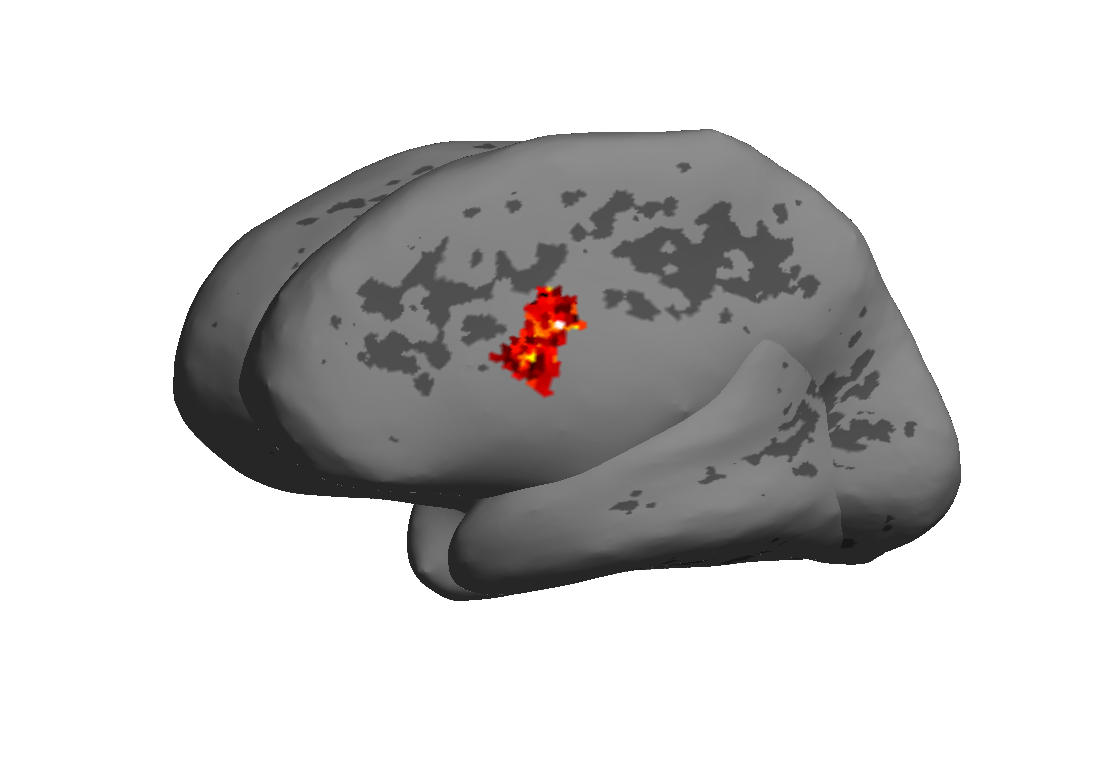

In [24]:
Image(filename='../sub-UTS01/derivative/preprocessed_data/subUTS01_stories_G_Frontal_Inf_Tri-1_correlmap.png')

#### 2.4.1 Attempt to use "cortex.Volume" (NOT WORKING !!!)
(Just kept the code below for the records)

In [ ]:
# The following was a tweak to get it working, but "S1" is not the same as "sub-UTS01" space !!!
# Therefore, the anatomical location of the ROI displayed is wrong !!!
# Did the following outside python:
#cp /opt/python3.13_venv/share/pycortex/db/S1/cache/S1_\[inflated\]_mg2_9_v3.* /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/
#cp /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/S1_\[inflated\]_mg2_9_v3.ctm /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/sub-UTS01_\[inflated\]_mg2_9_v3.ctm
#cp /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/S1_\[inflated\]_mg2_9_v3.json /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/sub-UTS01_\[inflated\]_mg2_9_v3.json
#cp /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/S1_\[inflated\]_mg2_9_v3.npz /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/sub-UTS01_\[inflated\]_mg2_9_v3.npz
#cp /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/S1_\[inflated\]_mg2_9_v3.svg /dati/cimec/zamparelli_LLMs/LeBelAetal2023_moth/sub-UTS01/cache/sub-UTS01_\[inflated\]_mg2_9_v3.svg
#Created a compressed copy of the reference.nii file: 'transforms/fullhead/reference.nii.gz' (symbolic link for 'derivative/pycortex-db/transforms/reference.nii.gz')

In [ ]:
#subUTS01_stories_roi_correlmap_nii_data = subUTS01_stories_roi_correlmap_nii.get_fdata()
#subUTS01_stories_roi_correlmap_nii_data.shape

In [ ]:
#subUTS01_stories_roi_correlmap_nii_data_swapped = subUTS01_stories_roi_correlmap_nii_data.swapaxes(0, 2)
#subUTS01_stories_roi_correlmap_nii_data_swapped.shape

In [ ]:
#subUTS01_stories_roi_correlmap_nii_data_swapped_vol = np.squeeze(subUTS01_stories_roi_correlmap_nii_data_swapped, axis=-1)
#subUTS01_stories_roi_correlmap_nii_data_swapped_vol.shape

In [ ]:
#subUTS01_stories_roi_correlmap_nii_data_swapped_vol[26,31,40:70]

In [ ]:
#f = figure(figsize=(10,10))
#cortex.mosaic(subUTS01_stories_roi_correlmap_nii_data_swapped_vol, cmap=cm.gray, interpolation="nearest");

In [ ]:
# NOT WORKING !!! Correlation maps are displayed on "S1" space, which is not the same as "sub-UTS01" space !!!
#corrvol = cortex.Volume(subUTS01_stories_roi_correlmap_nii_data_swapped_vol, "sub-UTS01", "fullhead", vmin=0, vmax = 1, cmap='hot')
#cortex.webgl.show(data=corrvol, with_rois = True)

## 3. Notes for the Group analysis

### Several ways how this could be done:
### - Use the "subUTS??_stories_G_Frontal_Inf_Tri-1_correlmap_MNI.nii.gz" images of all subjects, Z-score them, and run a one-sample 'fsl-randomize' test.
### - Extract mean correlation scores for each ROI, Z-score them, and run a one-sample t-test in R.

In [5]:
import os 
files = os.listdir("../moth_fMRI_by_ROI/")
files = [f for f in files if f.endswith('.nii')]
files

['G_Fusiform-4.nii',
 'G_Temporal_Mid-3.nii',
 'G_Temporal_Mid-4.nii',
 'G_ParaHippocampal-1.nii',
 'G_Temporal_Inf-4.nii',
 'G_Supp_Motor_Area-2.nii',
 'G_Supp_Motor_Area-3.nii',
 'G_Insula-anterior-2.nii',
 'G_Insula-anterior-3.nii',
 'G_Insula-anterior-1.nii',
 'G_Angular-2.nii',
 'N_Thalamus-4.nii',
 'G_Occipital_Inf-1.nii',
 'G_Temporal_Sup-4.nii',
 'G_Frontal_Inf_Orb-1.nii',
 'S_Sup_Temporal-4.nii',
 'G_Frontal_Inf_Tri-1.nii',
 'G_Cingulum_Post-3.nii',
 'S_Precentral-3.nii',
 'G_SupraMarginal-7.nii',
 'S_Precentral-4.nii',
 'S_Sup_Temporal-2.nii',
 'S_Sup_Temporal-3.nii',
 'S_Sup_Temporal-1.nii',
 'S_Inf_Frontal-2.nii',
 'G_Precuneus-6.nii',
 'G_Paracentral_Lobule-4.nii',
 'N_Amygdala-1.nii',
 'G_Frontal_Sup-2.nii',
 'N_Putamen-2.nii',
 'G_Hippocampus-2.nii',
 'N_Putamen-3.nii']